# **1. 규제 선형 회귀 모델/ 회귀 트리**
- 릿지 회귀모델 및 회귀 트리를 이용하여 전복의 나이를 예측해 보세요.

- 전복의 ‘성별’, ‘키’, ‘지름’, ‘높이’, ‘전체무게’, ‘몸통무게’, ‘내장무게’, ‘껍질무게’를 이용해 ‘껍질의 고리수’를 예측한 뒤, **예측된 ‘껍질의 고리수’에 1.5를 더하면 전복의 나이**가 됩니다.

In [1]:
# 기본 모듈 불러오기
import numpy as np
import pandas as pd

import warnings
warnings.filterwarnings(action='ignore')

### 1) 데이터 불러오기 및 데이터 선택

In [2]:
# 데이터 로드
data = pd.read_csv(r"C:\Users\user\ESAA_YB\abalone.csv")

# 성별 M은 Male, F는 Female, I는 Infant 이므로 따로 열 만들기
for label in "MFI":
    data[label] = data["Sex"] == label
data.drop('Sex', axis=1, inplace=True)

# X,y 데이터 선택
y = data.Rings.values
data.drop('Rings', axis=1, inplace=True)

X = data.values.astype(float)

## 2) train/test 분리
: 테스트 셋과 데이터 셋을 7:3 비율로 분리하세요.

In [3]:
# 필요한 모듈 불러오기
from sklearn.model_selection import train_test_split

In [4]:
# train과 test set 분리 (train:test = 7:3 비율)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

## 3) 릿지 모델을 이용한 모델링
: 릿지 모델을 이용하여 전복의 나이를 예측해 보고 결과를 평가해 보세요.

 3-1) 릿지모델 생성, 교차검증, 평가에 필요한 모듈을 불러오세요.

In [5]:
# 필요한 모듈 불러오기
from sklearn.linear_model import Ridge
from sklearn.model_selection import cross_val_score
from sklearn.metrics import mean_squared_error

3-2) 릿지 모델을 생성하고 훈련하여 MSE와 RMSE를 구하세요. 릿지 모델 생성 시  alpha는 0.3으로 설정합니다. (교차 검증 하지 않습니다.)

In [6]:
#릿지모델 생성 및 훈련
ridge = Ridge(alpha=0.3)
ridge.fit(X_train, y_train)

#예측값 구하기
pred_rings = ridge.predict(X_test)
pred_age = pred_rings + 1.5
actual_age = y_test + 1.5

#구한 예측값을 활용해 최종적으로 전복의 나이 예측


#MSE와 RMSE구하기

mse = mean_squared_error(actual_age, pred_age)
rmse = np.sqrt(mse)

print(mse, rmse)

5.013158686100952 2.239008415817357


3-3) 릿지 모델에서 회귀 계수 값을 구해 알 수 있는 점을 작성하시오. (각 컬럼의 정보는 data.colums 참고)

In [7]:
data.columns

Index(['Length', 'Diameter', 'Height', 'Whole weight', 'Shucked weight',
       'Viscera weight', 'Shell weight', 'M', 'F', 'I'],
      dtype='str')

In [24]:
coef_df = pd.DataFrame({
    'feature': data.columns,
    'coef': ridge.coef_,
}).sort_values(by='coef', ascending=False)

display(coef_df)
print('intercept_:', ridge.intercept_)

,feature,coef
6,Shell weight,10.532604
1,Diameter,8.561149
3,Whole weight,8.006314
2,Height,6.400273
0,Length,1.730623
7,M,0.330514
8,F,0.238986
9,I,-0.569500
5,Viscera weight,-8.934170
4,Shucked weight,-18.870049


intercept_: 3.8541924039681312


회귀계수의 부호로 나이와의 방향성을 파악할 수 있음, 강도로 영향력 비교 가능, 더미 변수 간의 차이 확인 가능

3-3) 교차검증을 이용하여 0, 0.1, 1, 10, 100 중  모델 성능이 가장 좋게 나오는 (rmse가 최소가 되는) alpha를 구하세요.

In [8]:
# 주어진 alpha
alphas=[0, 0.1, 1, 10, 100]

In [9]:
#alphas list 값을 반복하면서 alpha에 따른 평균 rmse를 구함


  #cross_val_score를 이용해 5 폴드의 평균 RMSE를 계산

for alpha in alphas:
  ridge_cv = Ridge(alpha=alpha)
  
  neg_mse_scores = cross_val_score(
      ridge_cv, X_train, y_train, scoring='neg_mean_squared_error', cv=5
  )
  rmse_scores = np.sqrt(-1 * neg_mse_scores)
  avg_rmse = np.mean(rmse_scores)
  print(f"alpha={alpha:>5} | 5-fold 평균 RMSE: {avg_rmse:.4f}")


alpha=    0 | 5-fold 평균 RMSE: 2.1921
alpha=  0.1 | 5-fold 평균 RMSE: 2.1890
alpha=    1 | 5-fold 평균 RMSE: 2.1920
alpha=   10 | 5-fold 평균 RMSE: 2.3360
alpha=  100 | 5-fold 평균 RMSE: 2.6042


알파가 0.1일 때 rmse가 최소가 된다. 

## 4) XGBRegressor을 이용한 모델링
: XGBRegressor 모델을 이용하여 전복의 나이를 예측해 보고 결과를 평가해 보세요.

4-1) XGBRegressor 훈련, 평가에 필요한 모듈을 불러오세요.

In [10]:
# 필요한 모듈 임포트
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error

4-2) XGBregressor 모델을 생성하고 훈련하여 MSE와 RMSE를 구하세요.

In [11]:
#모델 생성 및 훈련
xgb = XGBRegressor(random_state=0)
xgb.fit(X_train, y_train)

#예측값 구하기
xgb_pred_age = xgb.predict(X_test) + 1.5
actual_age = y_test + 1.5

#구한 예측값을 활용해 최종적으로 전복의 나이 예측


#MSE와 RMSE 구하기
xgb_mse = mean_squared_error(actual_age, xgb_pred_age)
xgb_rmse = np.sqrt(xgb_mse)
print(xgb_mse, xgb_rmse)

5.36271653425404 2.31575398828417


4-3) 생성한 모델의 피처 중요도를 시각화해보세요.

[Text(0.5, 1.0, 'XGBRegressor Feature Importances'),
 Text(0.5, 0, 'Feature Importance'),
 Text(0, 0.5, '')]

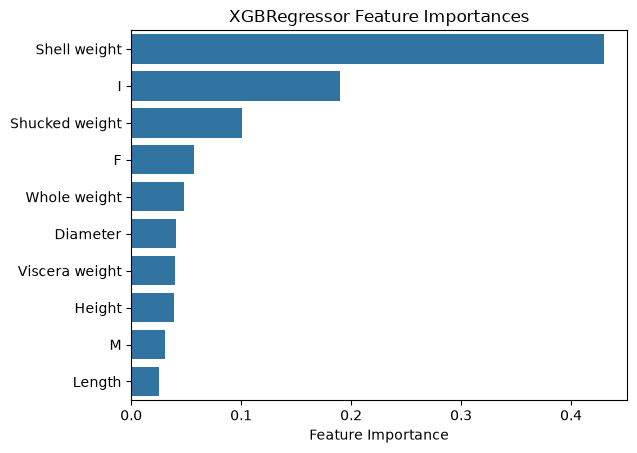

In [23]:
import seaborn as sns

%matplotlib inline

importances = pd.Series(
    xgb.feature_importances_, index=data.columns
).sort_values(ascending=False)

ax = sns.barplot(x=importances.values, y=importances.index)
ax.set(
    title='XGBRegressor Feature Importances', xlabel='Feature Importance', ylabel=''
)

---

# **2. 로지스틱 회귀분석**
load_wine() 함수를 이용하여 와인 데이터를 다항분류하는 로지스틱 회귀모델을 생성하세요.

In [13]:
# 필요한 모듈 불러오기
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn import metrics

## 1) 데이터 불러오기 및 변수 선택

In [14]:
wine = load_wine()

wine_x = wine.data # x변수
wine_y = wine.target # y변수

## 2) train/test 셋 분리

In [15]:
x_train, x_test, y_train, y_test = train_test_split(wine_x, wine_y, test_size=0.3, random_state=123)

x_train.shape
y_train.shape

(124,)

## 3) 로지스틱 회귀모델을 이용한 모델링

3-1) 로지스틱 회귀모델을 생성하여 훈련하세요.

In [18]:
from sklearn import set_config

set_config(display='text')

lr_clf = LogisticRegression(max_iter=5000, random_state=123)
lr_clf.fit(x_train, y_train)

LogisticRegression(max_iter=5000, random_state=123)

3-2) 회귀 모델의 기울기와 절편을 구하세요.

In [19]:
#기울기
print(lr_clf.coef_)

[[ 0.5098901   0.55258782  0.61975101 -0.2596534  -0.00123381  0.25320942
   0.75058494  0.08963842  0.15874357  0.19745347  0.00426488  0.51220245
   0.00873333]
 [-0.69155975 -0.92074664 -0.70501849  0.14928271 -0.04336082  0.3209202
   0.15632493  0.024514    0.37283172 -0.94459437  0.30494302  0.13116203
  -0.00776949]
 [ 0.18166965  0.36815882  0.08526747  0.11037069  0.04459463 -0.57412962
  -0.90690987 -0.11415242 -0.53157529  0.74714089 -0.3092079  -0.64336447
  -0.00096385]]


In [20]:
#절편
print(lr_clf.intercept_)

[-14.9552098   22.73457156  -7.77936176]


3-3) 모델의 정확도를 구하세요.

In [21]:
#모델의 예측값 구하기
y_pred = lr_clf.predict(x_test)

#모델의 정확도 구하기
accuracy = metrics.accuracy_score(y_test, y_pred)


In [22]:
print(y_pred)
print(accuracy)

[2 1 2 1 1 2 0 2 2 1 2 2 2 0 0 2 1 1 0 1 2 2 2 2 1 2 2 0 0 0 0 0 1 1 2 1 2
 0 1 1 2 2 0 0 1 0 0 1 0 1 1 2 2 1]
0.9629629629629629
